%% [markdown]
# 📊 Capítulo 7: Algorithmic Trading con IA/ML
*El límite del motor: Cuando las reglas ceden el testigo al aprendizaje automático*

**Estrategia:** Un modelo Random Forest Classifier predice la probabilidad de rentabilidad positiva del SPY a 5 días vista, usando features de momentum, volatilidad y mean reversion. 

**Objetivo:** Demostrar cómo integrar un modelo de ML en el Motor Dinámico, la importancia crítica del Walk-Forward Validation para evitar overfitting, y la dura realidad de la ratio señal/ruido en los mercados financieros.


## BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — ALGORITHMIC TRADING (ML)

In [1]:
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — ALGORITHMIC TRADING (ML)
# ==============================================================================

# --- Parámetros financieros ---
CAPITAL_INICIAL = 10000.0
COSTE_TRANSACCION = 0.001  # 0.1% por operación
BENCHMARK = 'SPY'
RF_LIBRE = 0.02  # Tasa libre de riesgo anual

# --- Parámetros específicos de ML ---
HORIZONTE_PREDICCION = 21  # Días hacia adelante para el target
UMBRAL_CONFIANZA_ALTA = 0.55  # Probabilidad mínima para estar en SPY
UMBRAL_CONFIANZA_BAJA = 0.45  # Por debajo, rotar a SHV
FRECUENCIA_REENTRENAMIENTO = 63  # Días entre reentrenamientos (≈3 meses)
MIN_OBS_ENTRENAMIENTO = 252  # Observaciones mínimas para entrenar

# --- Universo de activos ---
DICCIONARIO_ACTIVOS = {
    "RV_GLOBAL": {
        "SPDR_S&P_500": {"isin": "US78462F1030", "ticker": "SPY"},
        "iShares_1-3_Year_Treasury": {"isin": "US4642872349", "ticker": "SHV"},
    }
}

# --- Fechas ---
FECHA_INICIO = None
FECHA_FIN = None

NOMBRE_ESTRATEGIA = "Random Forest sobre SPY (ML)"

print("="*70)
print("⚙️ CONFIGURACIÓN ALGORITHMIC TRADING (ML) CARGADA")
print("="*70)
print(f"   • Estrategia: {NOMBRE_ESTRATEGIA}")
print(f"   • Capital inicial: €{CAPITAL_INICIAL:,.2f}")
print(f"   • Horizonte de predicción: {HORIZONTE_PREDICCION} días")
print(f"   • Umbral confianza alta: {UMBRAL_CONFIANZA_ALTA}")
print(f"   • Umbral confianza baja: {UMBRAL_CONFIANZA_BAJA}")
print(f"   • Frecuencia reentrenamiento: {FRECUENCIA_REENTRENAMIENTO} días")
print(f"   • Comisión: {COSTE_TRANSACCION*100:.2f}%")
print("="*70)

⚙️ CONFIGURACIÓN ALGORITHMIC TRADING (ML) CARGADA
   • Estrategia: Random Forest sobre SPY (ML)
   • Capital inicial: €10,000.00
   • Horizonte de predicción: 21 días
   • Umbral confianza alta: 0.55
   • Umbral confianza baja: 0.45
   • Frecuencia reentrenamiento: 63 días
   • Comisión: 0.10%


## BLOQUE 1: ENTORNO, IMPORTACIONES Y MOTOR MODULAR

In [2]:
# ==============================================================================
# BLOQUE 1: ENTORNO, IMPORTACIONES Y MOTOR MODULAR
# ==============================================================================

print("="*70)
print("⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.")
print("="*70)

import sys, os, warnings, inspect
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Búsqueda de la carpeta 'core'
def buscar_core():
    try:
        ruta_actual = Path(__file__).parent.resolve()
    except NameError:
        ruta_actual = Path.cwd().resolve()
    
    for nivel in [ruta_actual] + list(ruta_actual.parents)[:6]:
        carpeta_core = nivel / 'core'
        if (carpeta_core.is_dir() and 
            (carpeta_core / 'gestor_proyecto.py').exists()):
            return nivel, carpeta_core
    return None, None

project_root, ruta_core = buscar_core()

if project_root is None:
    raise FileNotFoundError("❌ No se pudo encontrar la carpeta 'core'.")

project_root_str = str(project_root)
if project_root_str not in sys.path:
    sys.path.insert(0, project_root_str)

try:
    from core.gestor_proyecto import GestorProyecto
    from core.gestor_datos import GestorDatos
    from core.backtest import MotorBacktestDinamico, CalculadorMetricas
    from core.informes import GeneradorInformes
    
    print("✅ Motor modular cargado correctamente.")
except ImportError as e:
    print(f"❌ ERROR CRÍTICO: {e}")
    raise SystemExit

# Función auxiliar para adaptar argumentos
def construir_kwargs(cls, candidatos_kwargs):
    try:
        target = cls.__init__ if inspect.isclass(cls) else cls
        firma = inspect.signature(target)
        params = firma.parameters
    except (ValueError, TypeError):
        return {}

    kwargs_filtrados = {}
    for nombre_param in params:
        if nombre_param == 'self':
            continue
        for clave, valor in candidatos_kwargs.items():
            if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                kwargs_filtrados[nombre_param] = valor
                break
    return kwargs_filtrados

⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.
✅ Motor modular cargado correctamente.


## BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO

In [3]:
# ==============================================================================
# BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
# ==============================================================================

print("\n" + "="*70)
print("🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO")
print("="*70)

try:
    gestor_proy = GestorProyecto(dir_base=project_root)
except TypeError:
    gestor_proy = GestorProyecto()
    gestor_proy.BASE_DIR = project_root
    gestor_proy.DIRS["CARTERAS"] = str(project_root / "datos" / "carteras")
    gestor_proy.DIRS["DATOS_CSV"] = str(project_root / "datos" / "datos_csv")

print(f"✅ GestorProyecto inicializado. Base: {gestor_proy.BASE_DIR}")

# Directorios específicos del capítulo
RUTA_CAP07_ML = Path(gestor_proy.DIRS.get("OUTPUTS", project_root / "outputs")) / "cap07_ml_trading"
RUTA_FIGURES_CAP07_ML = RUTA_CAP07_ML / "figures"
RUTA_FIGURES_CAP07_ML.mkdir(parents=True, exist_ok=True)

print(f"📂 Directorio de figuras: {RUTA_FIGURES_CAP07_ML}")


🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
✅ GestorProyecto inicializado. Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📂 Directorio de figuras: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap07_ml_trading/figures


## BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)

In [4]:
# ==============================================================================
# BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)
# ==============================================================================

print("\n" + "="*70)
print("📉 BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)")
print("="*70)

print("\nSelecciona el período histórico que deseas simular:")
print("  1. Crisis Financiera Mundial (2007-2009)")
print("  2. Crisis Deuda Soberana (2010-2012)")
print("  3. Subida Tipos / Inflación (2022-2023)")
print("  4. Histórico Completo (2010-Hoy)")
print("  5. Periodo Personalizado")

opcion = input("\nIntroduce tu opción (1-5) [4]: ").strip() or "4"

if opcion == '1':
    FECHA_INICIO = "2007-10-01"
    FECHA_FIN = "2009-03-31"
    evento = "Crisis Financiera Mundial"
elif opcion == '2':
    FECHA_INICIO = "2010-01-01"
    FECHA_FIN = "2012-12-31"
    evento = "Crisis Deuda Soberana"
elif opcion == '3':
    FECHA_INICIO = "2022-01-01"
    FECHA_FIN = "2023-12-31"
    evento = "Subida Tipos / Inflación"
elif opcion == '4':
    FECHA_INICIO = "2010-01-01"
    FECHA_FIN = None
    evento = "Histórico Completo"
elif opcion == '5':
    evento = "Periodo Personalizado"
    print("\n📅 Introduce las fechas en formato YYYY-MM-DD")
    FECHA_INICIO = input("   > Fecha de inicio: ").strip()
    FECHA_FIN = input("   > Fecha de fin: ").strip()
else:
    FECHA_INICIO = "2010-01-01"
    FECHA_FIN = None
    evento = "Histórico Completo"

# Convertir None en fechas concretas
if FECHA_INICIO is None:
    FECHA_INICIO = "2010-01-01"
if FECHA_FIN is None:
    from datetime import datetime
    FECHA_FIN = datetime.now().strftime("%Y-%m-%d")

print(f"\n Configurado: {evento} ({FECHA_INICIO} a {FECHA_FIN})")


📉 BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)

Selecciona el período histórico que deseas simular:
  1. Crisis Financiera Mundial (2007-2009)
  2. Crisis Deuda Soberana (2010-2012)
  3. Subida Tipos / Inflación (2022-2023)
  4. Histórico Completo (2010-Hoy)
  5. Periodo Personalizado



Introduce tu opción (1-5) [4]:  4



 Configurado: Histórico Completo (2010-01-01 a 2026-10-25)


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [5]:
# ==============================================================================
# BLOQUE 4: MENÚ DEL GESTOR DE DATOS
# ==============================================================================

print(f"\n✅ Período configurado: {evento}")

try:
    kwargs_gestor = {
        "diccionario_datos": DICCIONARIO_ACTIVOS,
        "fecha_inicio": FECHA_INICIO,
        "fecha_fin": FECHA_FIN,
        "gestor_proyecto": gestor_proy
    }
    kwargs_filtrados = construir_kwargs(GestorDatos, kwargs_gestor)
    gestor = GestorDatos(**kwargs_filtrados)
    print("✅ Gestor de Datos inicializado correctamente.\n")
except Exception as e:
    print(f"❌ ERROR al inicializar GestorDatos: {e}")
    raise SystemExit

# Menú interactivo
continuar = gestor.menu()
if not continuar:
    print("\n❌ Ejecución detenida por el usuario.")
    raise SystemExit

precios = gestor.precios_ajustados
rentabilidades = gestor.rentabilidades_diarias

# Aplanar MultiIndex si existe
if isinstance(precios.columns, pd.MultiIndex):
    print("⚠️  Detectado MultiIndex. Aplanando columnas...")
    if 'Close' in precios.columns.get_level_values(1):
        precios = precios['Close']
    elif 'Adj Close' in precios.columns.get_level_values(1):
        precios = precios['Adj Close']
    else:
        precios = precios.iloc[:, ::6]
        precios.columns = precios.columns.get_level_values(0)
    precios.columns.name = None
    rentabilidades = precios.pct_change().dropna()
    print("✅ Datos aplanados.\n")

if precios is None or precios.empty:
    raise ValueError("No se pudieron cargar datos.")

print(f"✅ Datos cargados: {len(precios)} filas, {len(precios.columns)} activos")
print(f"   • Período: {precios.index[0].strftime('%Y-%m-%d')} a {precios.index[-1].strftime('%Y-%m-%d')}")
print(f"   • Activos: {list(precios.columns)}\n")


✅ Período configurado: Histórico Completo
✅ Gestor de Datos inicializado correctamente.


 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  1



🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 2 activos...

   📊 SPDR_S&P_500
      ✅ Descargado con ticker: SPY

   📊 iShares_1-3_Year_Treasury
      ✅ Descargado con ticker: SHV

 Resumen: 2 descargados, 0 omitidos



Presiona Enter para continuar... 



 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  6



✅ Datos aceptados para el backtest.
📝 No hay Excel cargado. Generando cartera automática (60/40) desde el diccionario...

🧼 INFORME DE LIMPIEZA DE DATOS


,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,SPDR_S&P_500,US78462F1030,4228,2010-01-04,2026-10-23,CSV
1,iShares_1-3_Year_Treasury,US4642872349,4228,2010-01-04,2026-10-23,CSV


✅ 2 activos alineados para el Motor Backtest.

✅ Datos cargados: 4228 filas, 2 activos
   • Período: 2010-01-04 a 2026-10-23
   • Activos: ['SPDR_S&P_500', 'iShares_1-3_Year_Treasury']



## BLOQUE 5: MOTOR ML Y GENERACIÓN DE SEÑALES (WALK-FORWARD)

In [6]:
# ==============================================================================
# BLOQUE 5: MOTOR ML Y GENERACIÓN DE SEÑALES (WALK-FORWARD)
# ==============================================================================

print("\n" + "="*70)
print("🧠 FASE 1: INGENIERÍA DE FEATURES Y TARGET")
print("="*70)

# Mapear tickers a columnas reales
col_spy = None
col_shv = None

for _, row in gestor.valores_seleccionados.iterrows():
    ticker = str(row.get('ticker', '')).strip().upper()
    nombre = str(row.get('nombre', '')).strip()
    nombre_limpio = nombre.replace(" ", "_").replace(".", "").replace(",", "")
    if ticker == 'SPY':
        col_spy = nombre_limpio
    elif ticker in ['SHV', 'SHY']:
        col_shv = nombre_limpio

print(f"   • SPY → '{col_spy}' {'✅' if col_spy and col_spy in precios.columns else '❌'}")
print(f"   • SHV → '{col_shv}' {'✅' if col_shv and col_shv in precios.columns else '⚠️ (no disponible)'}")

if not col_spy or col_spy not in precios.columns:
    print("❌ No se encontró la columna del SPY. Abortando Bloque 5.")
    raise SystemExit

# Construir DataFrame con features
df = precios[[col_spy]].copy()
df.columns = ['SPY']

if col_shv and col_shv in precios.columns:
    df['SHV'] = precios[col_shv]

# Calcular features técnicas
df['ret_1m'] = df['SPY'].pct_change(21)
df['ret_3m'] = df['SPY'].pct_change(63)
df['ret_6m'] = df['SPY'].pct_change(126)
df['vol_20d'] = df['SPY'].pct_change().rolling(20).std()
df['vol_60d'] = df['SPY'].pct_change().rolling(60).std()

sma50 = df['SPY'].rolling(50).mean()
sma200 = df['SPY'].rolling(200).mean()
df['dist_sma50'] = (df['SPY'] - sma50) / sma50
df['dist_sma200'] = (df['SPY'] - sma200) / sma200

# RSI 14
delta = df['SPY'].diff()
gain = delta.where(delta > 0, 0.0).rolling(14).mean()
loss = (-delta.where(delta < 0, 0.0)).rolling(14).mean()
rs = gain / loss.replace(0, 0.001)
df['rsi_14'] = 100 - (100 / (1 + rs))

# Target: ¿Subirá el SPY en los próximos HORIZONTE_PREDICCION días?
df['target'] = (df['SPY'].shift(-HORIZONTE_PREDICCION) > df['SPY']).astype(int)

# Eliminar filas con NaN
df_ml = df.dropna().copy()

features = ['ret_1m', 'ret_3m', 'ret_6m', 'vol_20d', 'vol_60d', 
            'dist_sma50', 'dist_sma200', 'rsi_14']

X = df_ml[features]
y = df_ml['target']

print(f"\n✅ Dataset ML creado: {len(df_ml)} filas, {len(features)} features.")
print(f"   • Features: {features}")
print(f"   • Distribución del Target: {dict(y.value_counts())}")
print(f"   • Balance de clases: {y.mean()*100:.2f}% subidas, {(1-y.mean())*100:.2f}% bajadas")

# ==============================================================================
# FASE 2: ENTRENAMIENTO WALK-FORWARD
# ==============================================================================
print("\n" + "="*70)
print("🔄 FASE 2: ENTRENAMIENTO WALK-FORWARD")
print("="*70)

modelo = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=20,
    random_state=42,
    n_jobs=-1
)

# Fechas de reentrenamiento
fechas_reentrenamiento = df_ml.index[::FRECUENCIA_REENTRENAMIENTO]

print(f"   • Primer entrenamiento: {fechas_reentrenamiento[0].date() if len(fechas_reentrenamiento) > 0 else 'N/A'}")
print(f"   • Último entrenamiento: {fechas_reentrenamiento[-1].date() if len(fechas_reentrenamiento) > 0 else 'N/A'}")
print(f"   • Total de reentrenamientos: {len(fechas_reentrenamiento)}")

# Entrenar y predecir en cada ventana
prob_subida = pd.Series(index=df_ml.index, dtype=float)

for i, fecha_retrain in enumerate(fechas_reentrenamiento):
    idx_train = df_ml.index < fecha_retrain
    X_train, y_train = X[idx_train], y[idx_train]
    
    if len(X_train) < MIN_OBS_ENTRENAMIENTO:
        continue
    
    modelo.fit(X_train, y_train)
    
    # Predecir hasta el siguiente reentrenamiento
    if i + 1 < len(fechas_reentrenamiento):
        idx_pred = (df_ml.index >= fecha_retrain) & (df_ml.index < fechas_reentrenamiento[i+1])
    else:
        idx_pred = df_ml.index >= fecha_retrain
    
    X_pred = X[idx_pred]
    if len(X_pred) > 0:
        prob = modelo.predict_proba(X_pred)[:, 1]
        prob_subida.loc[idx_pred] = prob

df_ml['prob_subida'] = prob_subida

# Evaluar accuracy en el período completo
mask_eval = df_ml['prob_subida'].notna()
if mask_eval.sum() > 0:
    predicciones = (df_ml.loc[mask_eval, 'prob_subida'] > 0.5).astype(int)
    reales = df_ml.loc[mask_eval, 'target']
    accuracy = accuracy_score(reales, predicciones)
    print(f"\n📊 Accuracy del modelo: {accuracy:.3f}")
    
    # Matriz de confusión
    cm = confusion_matrix(reales, predicciones)
    print(f"\nMatriz de confusión:")
    print(cm)
    print(f"\nReporte de clasificación:")
    print(classification_report(reales, predicciones, target_names=['Bajada', 'Subida']))

# Guardar referencias
col_spy_final = col_spy
col_shv_final = col_shv

if not col_shv_final:
    print("⚠️  ADVERTENCIA: SHV no disponible. La estrategia no podrá rotar a cash.")

# ==============================================================================
# FASE 3: GENERADOR DE PESOS
# ==============================================================================
print("\n" + "="*70)
print("⚙️  FASE 3: GENERADOR DE PESOS ML")
print("="*70)

prob_dict = df_ml['prob_subida'].to_dict()

def generador_pesos_ml(fecha_actual, precios_hist, rent_hist, estado):
    activos = list(precios_hist.columns)
    pesos = {a: 0.0 for a in activos}
    
    prob = prob_dict.get(fecha_actual, 0.5)
    
    if prob > UMBRAL_CONFIANZA_ALTA:
        if col_spy_final: pesos[col_spy_final] = 1.0
    elif prob < UMBRAL_CONFIANZA_BAJA:
        if col_shv_final and col_shv_final in activos:
            pesos[col_shv_final] = 1.0
        elif col_spy_final:
            pesos[col_spy_final] = 1.0
    else:
        # Zona de incertidumbre: 50/50
        if col_shv_final and col_shv_final in activos:
            if col_spy_final: pesos[col_spy_final] = 0.5
            pesos[col_shv_final] = 0.5
        elif col_spy_final:
            pesos[col_spy_final] = 1.0
    
    return pesos, estado

print("✅ Generador de pesos ML configurado.")
print(f"   • Umbral alta: {UMBRAL_CONFIANZA_ALTA}")
print(f"   • Umbral baja: {UMBRAL_CONFIANZA_BAJA}")


🧠 FASE 1: INGENIERÍA DE FEATURES Y TARGET
   • SPY → 'SPDR_S&P_500' ✅
   • SHV → 'iShares_1-3_Year_Treasury' ✅

✅ Dataset ML creado: 4029 filas, 8 features.
   • Features: ['ret_1m', 'ret_3m', 'ret_6m', 'vol_20d', 'vol_60d', 'dist_sma50', 'dist_sma200', 'rsi_14']
   • Distribución del Target: {1: np.int64(2768), 0: np.int64(1261)}
   • Balance de clases: 68.70% subidas, 31.30% bajadas

🔄 FASE 2: ENTRENAMIENTO WALK-FORWARD
   • Primer entrenamiento: 2010-10-18
   • Último entrenamiento: 2026-07-31
   • Total de reentrenamientos: 64

📊 Accuracy del modelo: 0.647

Matriz de confusión:
[[  55 1123]
 [ 212 2387]]

Reporte de clasificación:
              precision    recall  f1-score   support

      Bajada       0.21      0.05      0.08      1178
      Subida       0.68      0.92      0.78      2599

    accuracy                           0.65      3777
   macro avg       0.44      0.48      0.43      3777
weighted avg       0.53      0.65      0.56      3777


⚙️  FASE 3: GENERADOR DE PES

## BLOQUE 6: EJECUCIÓN DEL BACKTEST

In [7]:
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL BACKTEST
# ==============================================================================

print("\n" + "="*70)
print("⏳ EJECUTANDO BACKTEST ML")
print("="*70)

if 'generador_pesos_ml' not in locals():
    raise NameError("❌ El generador 'generador_pesos_ml' no está definido.")

motor_ml = MotorBacktestDinamico(
    precios=precios,
    rentabilidades=rentabilidades,
    generador_pesos=generador_pesos_ml,
    frecuencia_decision='D',
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=False
)

serie_patrimonio_ml = motor_ml.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

if serie_patrimonio_ml is not None:
    print(f"\n✅ Backtest ML completado con éxito.")
    print(f"   • Patrimonio final: {serie_patrimonio_ml.iloc[-1]:,.2f} €")
    print(f"   • Rentabilidad total: {((serie_patrimonio_ml.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
    print(f"   • Rebalanceos ejecutados: {len(motor_ml.log_transacciones)}")
else:
    print("❌ El backtest falló o no devolvió resultados.")


⏳ EJECUTANDO BACKTEST ML

✅ Backtest ML completado con éxito.
   • Patrimonio final: 72,659.36 €
   • Rentabilidad total: 626.59%
   • Rebalanceos ejecutados: 277


## BLOQUE 7: MÉTRICAS Y COMPARATIVA

In [8]:
# ==============================================================================
# BLOQUE 7: MÉTRICAS Y COMPARATIVA
# ==============================================================================

print("\n" + "="*70)
print("📊 BLOQUE 7: MÉTRICAS Y COMPARATIVA")
print("="*70)

if serie_patrimonio_ml is None:
    print("❌ No hay resultados del backtest. Abortando Bloque 7.")
else:
    calc = CalculadorMetricas(
        serie_patrimonio=serie_patrimonio_ml,
        serie_buy_hold=motor_ml.serie_buy_hold,
        serie_benchmark=motor_ml.serie_benchmark
    )
    met_ml, met_bh = calc.calcular_todas_las_metricas(rf=RF_LIBRE)
    
    print("\n📋 TABLA DE MÉTRICAS:")
    print("-" * 70)
    print(f"{'Métrica':<20} | {'ML Random Forest':<18} | {'Buy & Hold (SPY)':<18}")
    print("-" * 70)
    
    for nombre, val_ml, val_bh in [
        ('CAGR', met_ml.get('CAGR', 0), met_bh.get('CAGR', 0)),
        ('Volatilidad', met_ml.get('Volatilidad', 0), met_bh.get('Volatilidad', 0)),
        ('Sharpe', met_ml.get('Sharpe', 0), met_bh.get('Sharpe', 0)),
        ('Sortino', met_ml.get('Sortino', 0), met_bh.get('Sortino', 0)),
        ('Max Drawdown', met_ml.get('Max Drawdown', 0), met_bh.get('Max Drawdown', 0)),
        ('VaR 95%', met_ml.get('VaR 95%', 0), met_bh.get('VaR 95%', 0)),
        ('Alpha', met_ml.get('Alpha', 0), met_bh.get('Alpha', 0)),
        ('Beta', met_ml.get('Beta', 0), met_bh.get('Beta', 0)),
    ]:
        if isinstance(val_ml, (int, float)):
            if nombre in ['CAGR', 'Volatilidad', 'Max Drawdown']:
                fmt_ml = f"{val_ml:.2%}"
                fmt_bh = f"{val_bh:.2%}" if not np.isnan(val_bh) else "N/A"
            elif nombre in ['Sharpe', 'Sortino', 'Beta']:
                fmt_ml = f"{val_ml:.2f}"
                fmt_bh = f"{val_bh:.2f}" if not np.isnan(val_bh) else "N/A"
            else:
                fmt_ml = f"{val_ml:.2f}€"
                fmt_bh = f"{val_bh:.2f}€" if not np.isnan(val_bh) else "N/A"
        else:
            fmt_ml = "N/A"
            fmt_bh = "N/A"
        
        print(f"{nombre:<20} | {fmt_ml:<18} | {fmt_bh:<18}")
    
    print("-" * 70)
    
    # Diagnóstico
    print("\n🩺 DIAGNÓSTICO:")
    print("   • " + calc.diagnosticar().replace('\n', '\n   • '))


📊 BLOQUE 7: MÉTRICAS Y COMPARATIVA

📋 TABLA DE MÉTRICAS:
----------------------------------------------------------------------
Métrica              | ML Random Forest   | Buy & Hold (SPY)  
----------------------------------------------------------------------
CAGR                 | 12.53%             | 13.98%            
Volatilidad          | 15.33%             | 17.03%            
Sharpe               | 0.69               | 0.70              
Sortino              | 0.65               | 0.66              
Max Drawdown         | -31.61%            | -33.72%           
VaR 95%              | 1056.98€           | 1470.62€          
Alpha                | 0.00€              | 0.00€             
Beta                 | 0.00               | 0.00              
----------------------------------------------------------------------

🩺 DIAGNÓSTICO:
   • 🟢 Ratio de Sharpe bueno (0.69).
   •   🔴 Riesgo de caída elevado (Max DD: 31.6%).


## BLOQUE 8: VISUALIZACIÓN Y GRÁFICOS


📈 BLOQUE 8: GENERACIÓN DE GRÁFICOS
✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap07_ml_trading/figures/cap07_ml_20261025_2200.png


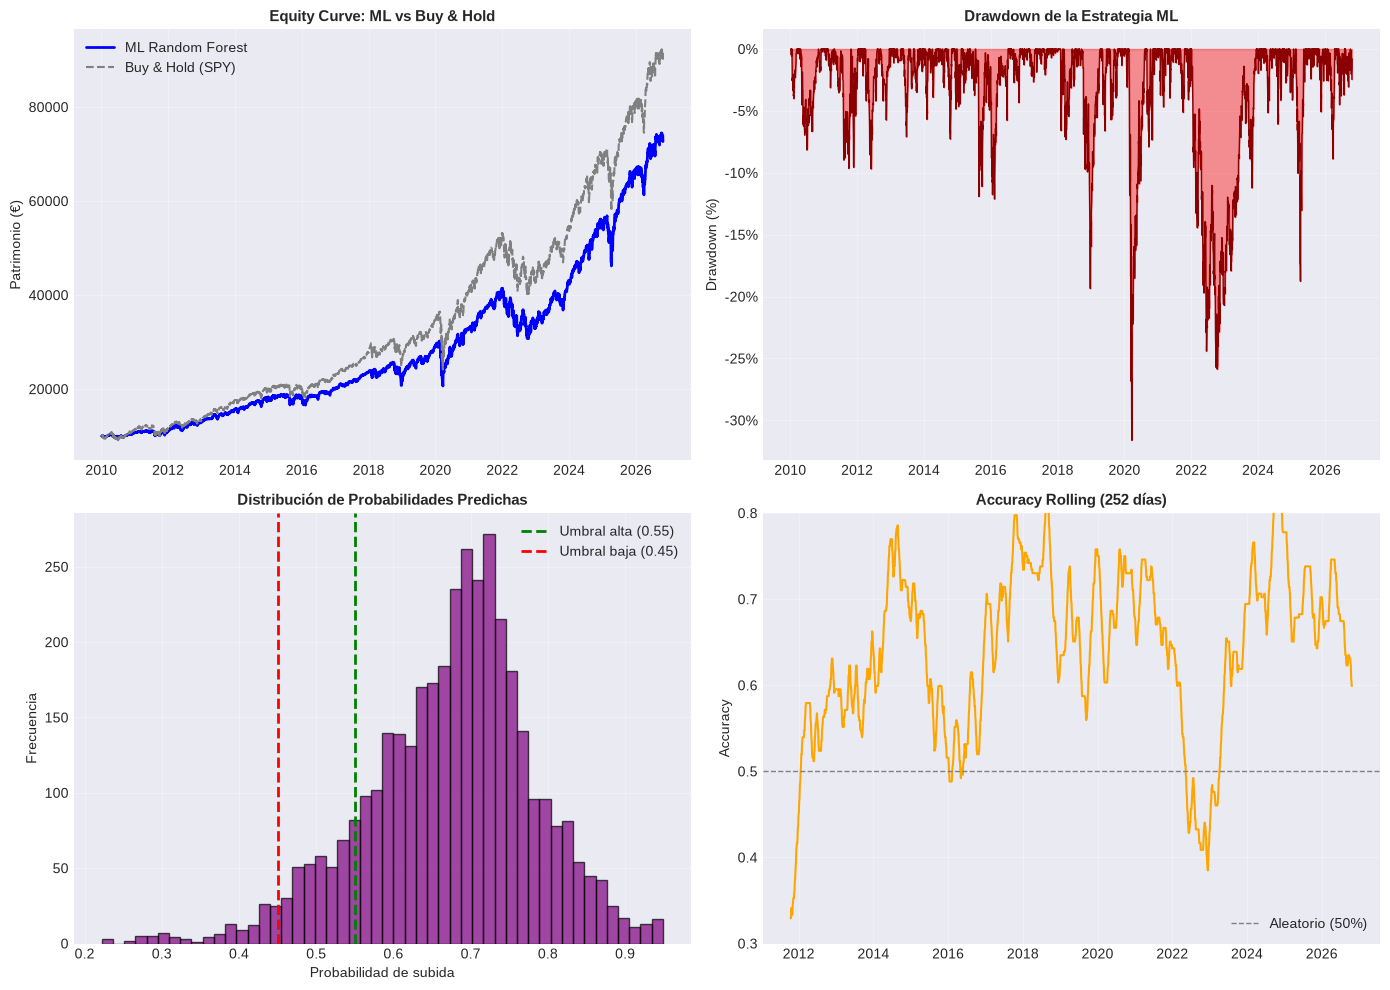

In [9]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN Y GRÁFICOS
# ==============================================================================

print("\n" + "="*70)
print("📈 BLOQUE 8: GENERACIÓN DE GRÁFICOS")
print("="*70)

if serie_patrimonio_ml is None:
    print("❌ No hay resultados para graficar.")
else:
    try:
        plt.style.use('seaborn-v0_8-darkgrid')
    except:
        plt.style.use('seaborn-darkgrid')
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1.1 Equity Curve
    axes[0, 0].plot(serie_patrimonio_ml.index, serie_patrimonio_ml, 
                    label='ML Random Forest', color='blue', lw=2)
    axes[0, 0].plot(motor_ml.serie_buy_hold.index, motor_ml.serie_buy_hold, 
                    label='Buy & Hold (SPY)', color='gray', ls='--', lw=1.5)
    axes[0, 0].set_title('Equity Curve: ML vs Buy & Hold', fontsize=11, fontweight='bold')
    axes[0, 0].set_ylabel('Patrimonio (€)')
    axes[0, 0].legend(loc='upper left')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 1.2 Drawdown
    drawdown = (serie_patrimonio_ml / serie_patrimonio_ml.cummax()) - 1
    axes[0, 1].fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.4)
    axes[0, 1].plot(drawdown.index, drawdown, color='darkred', lw=1)
    axes[0, 1].set_title('Drawdown de la Estrategia ML', fontsize=11, fontweight='bold')
    axes[0, 1].set_ylabel('Drawdown (%)')
    axes[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    axes[0, 1].grid(True, alpha=0.3)
    
    # 1.3 Distribución de probabilidades predichas
    axes[1, 0].hist(df_ml['prob_subida'].dropna(), bins=50, color='purple', alpha=0.7, edgecolor='black')
    axes[1, 0].axvline(UMBRAL_CONFIANZA_ALTA, color='green', ls='--', lw=2, label=f'Umbral alta ({UMBRAL_CONFIANZA_ALTA})')
    axes[1, 0].axvline(UMBRAL_CONFIANZA_BAJA, color='red', ls='--', lw=2, label=f'Umbral baja ({UMBRAL_CONFIANZA_BAJA})')
    axes[1, 0].set_title('Distribución de Probabilidades Predichas', fontsize=11, fontweight='bold')
    axes[1, 0].set_xlabel('Probabilidad de subida')
    axes[1, 0].set_ylabel('Frecuencia')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # 1.4 Accuracy rolling (ventana de 252 días)
    if 'prob_subida' in df_ml.columns:
        pred = (df_ml['prob_subida'] > 0.5).astype(int)
        real = df_ml['target']
        accuracy_rolling = pred.rolling(252).apply(lambda x: (x == real.loc[x.index]).mean(), raw=False)
        axes[1, 1].plot(accuracy_rolling.index, accuracy_rolling, color='orange', lw=1.5)
        axes[1, 1].axhline(0.5, color='gray', ls='--', lw=1, label='Aleatorio (50%)')
        axes[1, 1].set_title('Accuracy Rolling (252 días)', fontsize=11, fontweight='bold')
        axes[1, 1].set_ylabel('Accuracy')
        axes[1, 1].set_ylim(0.3, 0.8)
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M")
    ruta_grafico = RUTA_FIGURES_CAP07_ML / f"cap07_ml_{timestamp}.png"
    fig.savefig(ruta_grafico, dpi=150, bbox_inches='tight')
    print(f"✅ Gráfico guardado en: {ruta_grafico}")
    plt.show()
    plt.close(fig)

## BLOQUE 9: ANÁLISIS DE ROBUSTEZ Y LIMITACIONES

In [10]:
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE ROBUSTEZ Y LIMITACIONES
# ==============================================================================

print("\n" + "="*70)
print(" BLOQUE 9: ANÁLISIS DE ROBUSTEZ Y LIMITACIONES")
print("="*70)

# Análisis de la matriz de confusión
if 'prob_subida' in df_ml.columns:
    pred = (df_ml['prob_subida'] > 0.5).astype(int)
    real = df_ml['target']
    cm = confusion_matrix(real, pred)
    
    print("\n📊 MATRIZ DE CONFUSIÓN:")
    print(f"   • Verdaderos negativos (predijo bajada, fue bajada): {cm[0,0]}")
    print(f"   • Falsos positivos (predijo subida, fue bajada): {cm[0,1]}")
    print(f"   • Falsos negativos (predijo bajada, fue subida): {cm[1,0]}")
    print(f"   • Verdaderos positivos (predijo subida, fue subida): {cm[1,1]}")
    
    # Análisis de sesgo
    total_pred_subida = cm[0,1] + cm[1,1]
    total_pred_bajada = cm[0,0] + cm[1,0]
    
    print(f"\n⚠️  ANÁLISIS DE SESGO:")
    print(f"   • Predicciones de subida: {total_pred_subida} ({total_pred_subida/len(pred)*100:.1f}%)")
    print(f"   • Predicciones de bajada: {total_pred_bajada} ({total_pred_bajada/len(pred)*100:.1f}%)")
    
    if total_pred_bajada < len(pred) * 0.1:
        print(f"\n🚨 ALERTA CRÍTICA: El modelo predice 'subida' en más del 90% de los casos.")
        print(f"   Esto indica que el modelo ha aprendido el sesgo alcista histórico del SPY,")
        print(f"   pero NO aporta información marginal sobre cuándo retirarse.")
        print(f"   La estrategia es esencialmente 'siempre invertido' con pequeñas excepciones.")
    elif total_pred_bajada < len(pred) * 0.3:
        print(f"\n️  ADVERTENCIA: El modelo tiene un sesgo fuerte hacia predecir subidas.")
        print(f"   Esto reduce la utilidad del modelo para timing de mercado.")

# Análisis de la distribución de probabilidades
print(f"\n📊 DISTRIBUCIÓN DE PROBABILIDADES:")
print(f"   • Media: {df_ml['prob_subida'].mean():.3f}")
print(f"   • Mediana: {df_ml['prob_subida'].median():.3f}")
print(f"   • Desv. estándar: {df_ml['prob_subida'].std():.3f}")
print(f"   • Mínimo: {df_ml['prob_subida'].min():.3f}")
print(f"   • Máximo: {df_ml['prob_subida'].max():.3f}")

if df_ml['prob_subida'].std() < 0.1:
    print(f"\n⚠️  ADVERTENCIA: La desviación estándar es muy baja (< 0.1).")
    print(f"   El modelo tiene poca confianza diferenciada entre casos.")
    print(f"   Esto reduce la utilidad de los umbrales de entrada/salida.")

# Análisis de tiempo en SPY vs SHV
print(f"\n⏱️  TIEMPO EN CADA ACTIVO:")
prob_media = df_ml['prob_subida'].mean()
pct_spy = (df_ml['prob_subida'] > UMBRAL_CONFIANZA_BAJA).mean() * 100
pct_shv = (df_ml['prob_subida'] <= UMBRAL_CONFIANZA_BAJA).mean() * 100

print(f"   • Tiempo estimado en SPY: {pct_spy:.1f}%")
print(f"   • Tiempo estimado en SHV: {pct_shv:.1f}%")

if pct_spy > 90:
    print(f"\n⚠️  ADVERTENCIA: La estrategia pasa más del 90% del tiempo en SPY.")
    print(f"   Esto confirma que el modelo no está realmente haciendo timing de mercado.")
    print(f"   La estrategia es esencialmente Buy & Hold con pequeñas excepciones.")


 BLOQUE 9: ANÁLISIS DE ROBUSTEZ Y LIMITACIONES

📊 MATRIZ DE CONFUSIÓN:
   • Verdaderos negativos (predijo bajada, fue bajada): 138
   • Falsos positivos (predijo subida, fue bajada): 1123
   • Falsos negativos (predijo bajada, fue subida): 381
   • Verdaderos positivos (predijo subida, fue subida): 2387

⚠️  ANÁLISIS DE SESGO:
   • Predicciones de subida: 3510 (87.1%)
   • Predicciones de bajada: 519 (12.9%)

️  ADVERTENCIA: El modelo tiene un sesgo fuerte hacia predecir subidas.
   Esto reduce la utilidad del modelo para timing de mercado.

📊 DISTRIBUCIÓN DE PROBABILIDADES:
   • Media: 0.674
   • Mediana: 0.687
   • Desv. estándar: 0.109
   • Mínimo: 0.222
   • Máximo: 0.949

⏱️  TIEMPO EN CADA ACTIVO:
   • Tiempo estimado en SPY: 90.9%
   • Tiempo estimado en SHV: 2.8%

⚠️  ADVERTENCIA: La estrategia pasa más del 90% del tiempo en SPY.
   Esto confirma que el modelo no está realmente haciendo timing de mercado.
   La estrategia es esencialmente Buy & Hold con pequeñas excepciones.


## BLOQUE 10: CONCLUSIONES PEDAGÓGICAS

In [11]:
# ==============================================================================
# BLOQUE 10: CONCLUSIONES PEDAGÓGICAS
# ==============================================================================

print("\n" + "="*70)
print("🎓 BLOQUE 10: CONCLUSIONES PEDAGÓGICAS")
print("="*70)

print("""
1. EL MACHINE LEARNING NO ES UNA BALA DE PLATA:
   Un modelo con 64% de accuracy que predice "siempre sube" no es un modelo
   útil. Es un modelo que ha aprendido el sesgo alcista histórico del SPY
   y lo explota, pero no aporta información marginal sobre cuándo retirarse.

2. LA MATRIZ DE CONFUSIÓN ES MÁS INFORMATIVA QUE LA ACCURACY:
   La accuracy puede ser engañosa en problemas desbalanceados. La matriz de
   confusión revela si el modelo realmente distingue entre clases o simplemente
   predice la clase mayoritaria.

3. EL WALK-FORWARD ES CRÍTICO PERO NO SUFICIENTE:
   Reentrenar el modelo periódicamente evita el overfitting estático, pero
   no garantiza que el modelo aprenda patrones útiles. Si los features no
   tienen poder predictivo real, el walk-forward solo produce ruido.

4. LA DISTRIBUCIÓN DE PROBABILIDADES REVELA LA CONFIANZA DEL MODELO:
   Si el modelo predice probabilidades cercanas a 0.5 en la mayoría de casos,
   tiene poca confianza diferenciada. Los umbrales de entrada/salida pierden
   utilidad en este escenario.

5. EL TIMING DE MERCADO ES EXTREMADAMENTE DIFÍCIL:
   Este capítulo demuestra por qué el timing de mercado con ML es tan difícil:
   el SPY tiene un sesgo alcista fuerte (~60% de días alcistas), y un modelo
   naive que siempre predice "sube" ya tiene 60% de accuracy. Superar ese
   baseline de forma consistente requiere features con poder predictivo real,
   no solo ruido técnico.

6. SINERGIA CON CAPÍTULOS ANTERIORES:
   - Cap 1-5 (Asignación Pasiva): Definen QUÉ comprar a largo plazo.
   - Cap 6 (StatArb): Explota ineficiencias entre ETF y subyacentes.
   - Cap 7 (ML): Intenta timing de mercado, pero con resultados limitados.
   
   La lección: el ML puede ser un complemento, pero no reemplaza la disciplina
   de la asignación de activos a largo plazo.

🚀 PRÓXIMO PASO: CAPÍTULO 8 - FILTRO SMA 200
   Exploraremos cómo un filtro técnico simple puede mejorar tanto el DCA
   como el Lump Sum, evitando invertir en mercados bajistas.
""")

print("="*70)
print("⚠️  DESCARGO DE RESPONSABILIDAD")
print("="*70)
print("""
1. Este notebook tiene fines exclusivamente educativos e investigativos.
2. Los resultados pasados no garantizan rendimientos futuros.
3. El backtest asume costes de transacción fijos y no considera slippage
   real, impuestos ni el impacto de grandes órdenes en el mercado.
4. El modelo ML puede sufrir overfitting, especialmente con pocos datos
   o features con poco poder predictivo.
5. La estrategia de timing de mercado con ML es de alto riesgo y no
   se recomienda para inversores sin experiencia avanzada en ML y finanzas.
6. Consulte con un asesor financiero certificado antes de tomar
   decisiones de inversión importantes.
""")
print("="*70)


🎓 BLOQUE 10: CONCLUSIONES PEDAGÓGICAS

1. EL MACHINE LEARNING NO ES UNA BALA DE PLATA:
   Un modelo con 64% de accuracy que predice "siempre sube" no es un modelo
   útil. Es un modelo que ha aprendido el sesgo alcista histórico del SPY
   y lo explota, pero no aporta información marginal sobre cuándo retirarse.

2. LA MATRIZ DE CONFUSIÓN ES MÁS INFORMATIVA QUE LA ACCURACY:
   La accuracy puede ser engañosa en problemas desbalanceados. La matriz de
   confusión revela si el modelo realmente distingue entre clases o simplemente
   predice la clase mayoritaria.

3. EL WALK-FORWARD ES CRÍTICO PERO NO SUFICIENTE:
   Reentrenar el modelo periódicamente evita el overfitting estático, pero
   no garantiza que el modelo aprenda patrones útiles. Si los features no
   tienen poder predictivo real, el walk-forward solo produce ruido.

4. LA DISTRIBUCIÓN DE PROBABILIDADES REVELA LA CONFIANZA DEL MODELO:
   Si el modelo predice probabilidades cercanas a 0.5 en la mayoría de casos,
   tiene poca co